# Кейс 2. Прогнозирование оттока (Предзащита)

**Цель:** предсказать вероятность оттока `Отток ∈ {0,1}` и выделить факторы риска.
**Метрика:** ROC-AUC (главная) + Recall (полнота) класса «ушёл».
**Почему не Accuracy:** дисбаланс классов (73% остаются / 27% уходят). Accuracy 73% покажет «глупая» модель.
**План предзащиты:** EDA -> Pipeline -> Baseline (LogisticRegression) -> План работ на защиту.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import sys
sys.path.append('..') # Чтобы видеть папку src
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.data_utils import load_and_clean

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, classification_report

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

In [7]:
df = load_and_clean()
print(f"Размер данных: {df.shape}")
print(f"Доля ушедших: {df['Отток'].mean():.1%}")
# Выведем 22 дубликата (оставляем, т.к. это разные customerID)
print(f"Дубликатов по признакам: {df.duplicated().sum()}")

Размер данных: (7043, 20)
Доля ушедших: 26.5%
Дубликатов по признакам: 22


## 2. Быстрый EDA
Смотрим на ключевые сегменты. 

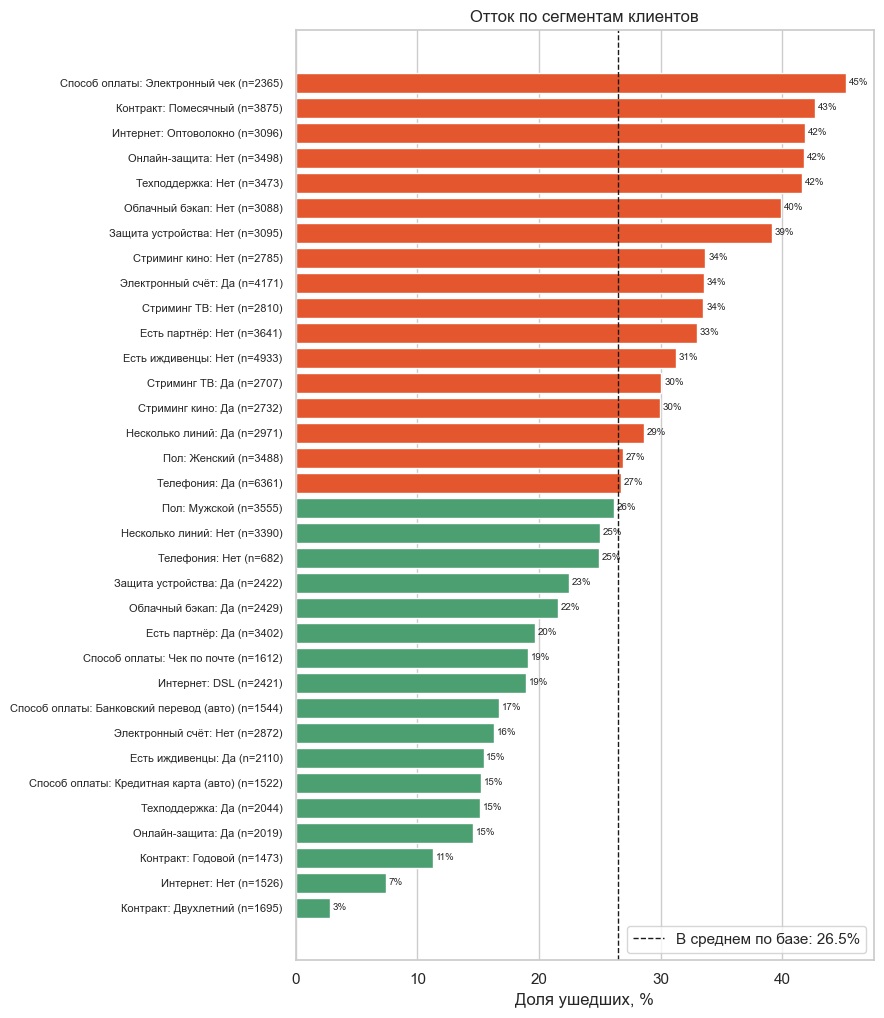

In [8]:
# Определяем цвета, чтобы график работал корректно
palette = {"Остался": "#4c9f70", "Ушёл": "#e4572e"}

base = df["Отток"].mean() * 100
parts = []
for col in df.select_dtypes("category").columns:
    g = df.groupby(col, observed=True)["Отток"].agg(rate="mean", n="size")
    g = g.drop(index=["Нет интернета", "Нет телефонии"], errors="ignore")   # эти группы = «Интернет: Нет» / «Телефония: Нет», не повторяем 7 раз
    g.index = [f"{col}: {v} (n={n})" for v, n in zip(g.index, g["n"])]
    parts.append(g)
    
seg = pd.concat(parts).sort_values("rate")
seg["rate"] *= 100

# Построение графика
fig, ax = plt.subplots(figsize=(9, 0.26 * len(seg) + 1.5))
ax.barh(seg.index, seg["rate"], color=np.where(seg["rate"] > base, palette["Ушёл"], palette["Остался"]))
ax.bar_label(ax.containers[0], fmt="%.0f%%", fontsize=7, padding=2)
ax.axvline(base, color="k", ls="--", lw=1, label=f"В среднем по базе: {base:.1f}%")

ax.set_xlabel("Доля ушедших, %")
ax.set_title("Отток по сегментам клиентов")
ax.legend(loc="lower right")
ax.tick_params(axis="y", labelsize=8)
ax.grid(axis="y", visible=False)

plt.tight_layout()
plt.show() # Обязательно, чтобы график отрисовался в ноутбуке

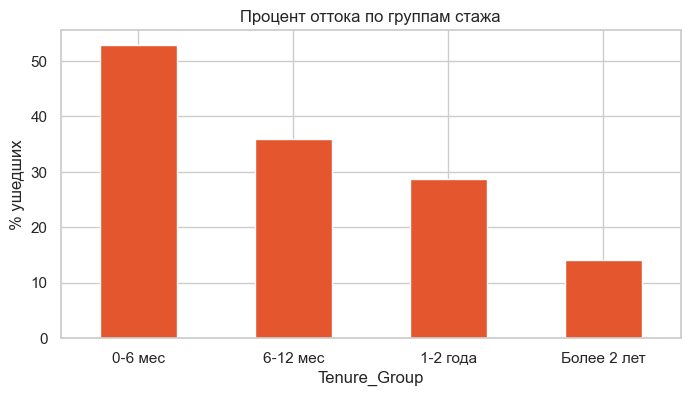

In [9]:
df['Tenure_Group'] = pd.cut(df['Стаж'], bins=[-1, 6, 12, 24, 100], 
                            labels=["0-6 мес", "6-12 мес", "1-2 года", "Более 2 лет"])

churn_by_tenure = df.groupby('Tenure_Group', observed=True)['Отток'].mean() * 100
plt.figure(figsize=(8, 4))
churn_by_tenure.plot(kind='bar', color='#e4572e')
plt.title('Процент оттока по группам стажа')
plt.ylabel('% ушедших')
plt.xticks(rotation=0)
plt.show()

## Инсайты EDA
1. **Помесячный контракт** и **Электронный чек** — зона высокого риска.
2. **Новички (до 6 мес)** уходят чаще всего (>50%). 
3. **Оптоволокно** повышает риск оттока.
*Дальше обучим модель и проверим, подтвердит ли она эти инсайты.*

In [10]:
X = df.drop(columns=["Отток", "Tenure_Group"])
y = df["Отток"]

cat_cols = X.select_dtypes("category").columns.tolist()
num_cols = X.select_dtypes("number").columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat_cols),
    ("num", StandardScaler(), num_cols),
])

print(f"Train: {X_train.shape}, Test: {X_test.shape}")

Train: (5634, 19), Test: (1409, 19)


In [11]:
# Обучаем логистическую регрессию (class_weight сбалансирует классы)
pipe_lr = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=RANDOM_STATE))
])

pipe_lr.fit(X_train, y_train)
y_proba = pipe_lr.predict_proba(X_test)[:, 1]

print(f"ROC-AUC: {roc_auc_score(y_test, y_proba):.3f}")
print(classification_report(y_test, (y_proba >= 0.5).astype(int), target_names=["Остался", "Ушёл"]))

ROC-AUC: 0.842
              precision    recall  f1-score   support

     Остался       0.90      0.72      0.80      1035
        Ушёл       0.50      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



## 4. Итоги предзащиты
- Baseline (LogReg) обучен. ROC-AUC ~ 0.84.
- Recall по ушедшим на пороге 0.5 пока ниже желаемого.

**Что будет сделано к защите:**
1. Обучение RandomForest и GradientBoosting.
2. Построение ROC-кривых для сравнения.
3. Подбор оптимального порога (threshold) для максимизации Recall.
4. Интерпретация модели через SHAP (факторы риска).
5. Формирование списка клиентов в зоне риска.